# Cloud Workload Forecasting - Model Selection

I compare simple models on the training window only (first 110 timestamps).
The 24-step holdout is not used here.

In [1]:
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from cwfc.data import build_targets, load_readings, split_train_holdout
from cwfc.evaluation import backtest, compare_models, rolling_origins
from cwfc.models import moving_average_forecast, persistence_forecast, ridge_ar_forecast

data_dir = Path("challenge_data")
if not data_dir.exists():
    data_dir = Path("../challenge_data")

targets = build_targets(load_readings(data_dir))
train, holdout = split_train_holdout(targets)
del holdout  # not used for model selection

print(len(train), "training timestamps")

110 training timestamps


## Validation design
Rolling origin: at each origin, the model sees only the past and forecasts the next 24 steps (2 hours),
the same horizon as the holdout. Origins move forward by 6 steps (30 minutes).
This copies production: forecast the next 2 hours with the data available now.

In [2]:
HORIZON, MIN_TRAIN, STEP = 24, 48, 6
origins = rolling_origins(len(train), HORIZON, MIN_TRAIN, STEP)
print("Origins:", origins, "->", len(origins), "folds")

Origins: [48, 54, 60, 66, 72, 78, 84] -> 7 folds


In [3]:
candidates = {
    "persistence": persistence_forecast,
    "moving_average_6": partial(moving_average_forecast, window=6),
    "moving_average_12": partial(moving_average_forecast, window=12),
    "moving_average_24": partial(moving_average_forecast, window=24),
    "ridge_ar_lags3": partial(ridge_ar_forecast, n_lags=3, alpha=1.0),
    "ridge_ar_lags6": partial(ridge_ar_forecast, n_lags=6, alpha=1.0),
    "ridge_ar_lags12": partial(ridge_ar_forecast, n_lags=12, alpha=1.0),
}

cpu_series = train["aggregate_cpu_utilization"].to_numpy()
cpu_results = compare_models(cpu_series, candidates, horizon=HORIZON, min_train=MIN_TRAIN, step=STEP)
pd.set_option("display.width", 200)
cpu_results.round(4)

,mae,rmse,mae_fold_std,folds_won_vs_baseline,mae_vs_baseline
ridge_ar_lags3,0.1983,0.2414,0.0732,4.0,0.7467
ridge_ar_lags6,0.2020,0.2435,0.0694,4.0,0.7608
ridge_ar_lags12,0.2443,0.2886,0.0754,5.0,0.9202
moving_average_6,0.2532,0.3051,0.1050,4.0,0.9537
persistence,0.2655,0.3174,0.1118,0.0,1.0000
moving_average_12,0.2688,0.3121,0.0971,4.0,1.0124
moving_average_24,0.2789,0.3108,0.0659,2.0,1.0503


In [4]:
count_series = train["active_vm_count"].to_numpy()
compare_models(count_series, candidates, horizon=HORIZON, min_train=MIN_TRAIN, step=STEP).round(4)

,mae,rmse,mae_fold_std,folds_won_vs_baseline,mae_vs_baseline
persistence,0.0,0.0,0.0,0.0,1.0
moving_average_6,0.0,0.0,0.0,0.0,1.0
moving_average_12,0.0,0.0,0.0,0.0,1.0
moving_average_24,0.0,0.0,0.0,0.0,1.0
ridge_ar_lags3,0.0,0.0,0.0,0.0,1.0
ridge_ar_lags6,0.0,0.0,0.0,0.0,1.0
ridge_ar_lags12,0.0,0.0,0.0,0.0,1.0


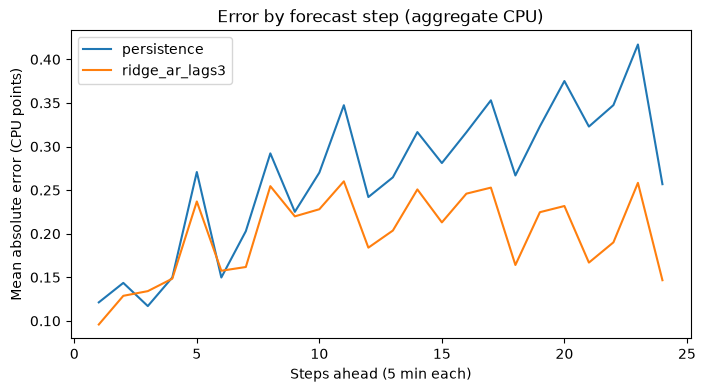

In [5]:
best = cpu_results.index[0]
fig, ax = plt.subplots(figsize=(8, 4))
for name in dict.fromkeys(["persistence", best]):
    bt = backtest(cpu_series, candidates[name], horizon=HORIZON, min_train=MIN_TRAIN, step=STEP)
    error_by_step = (bt["actual"] - bt["forecast"]).abs().groupby(bt["step_ahead"]).mean()
    error_by_step.plot(ax=ax, label=name)
ax.set_xlabel("Steps ahead (5 min each)")
ax.set_ylabel("Mean absolute error (CPU points)")
ax.set_title("Error by forecast step (aggregate CPU)")
ax.legend()

# Save the figure for the final report
figures_dir = data_dir.parent / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figures_dir / "error_by_step.png", dpi=150, bbox_inches="tight")

plt.show()

**What I see:**
- Aggregate CPU: `ridge_ar_lags3` has the lowest error (MAE 0.198 vs 0.266 for persistence, 25% lower; RMSE 0.241 vs 0.317).
  It is also more stable across folds (MAE std 0.073 vs 0.112).
- It beats persistence on only 4 of 7 folds, so the gain is real but not uniform: it comes mostly from some periods.
- Both models are close for the first 4 steps (20 min). After that, persistence error keeps growing,
  while ridge error stays lower because it pulls the forecast back toward the recent mean.
- `ridge_ar_lags6` is almost as good (MAE 0.202). I keep 3 lags because it is the simplest of the two.
- Active VM count: every model has zero error because the series is constant. I keep persistence.

**Decision:** `ridge_ar_lags3` for aggregate CPU, persistence for active VM count, persistence as the baseline.

## Sensitivity to the ridge penalty
I check that the result does not depend on the choice alpha = 1 (training window only).

In [6]:
alpha_results = {}
for alpha in [0.1, 1.0, 10.0, 100.0]:
    forecaster = partial(ridge_ar_forecast, n_lags=3, alpha=alpha)
    table = compare_models(
        cpu_series,
        {"persistence": persistence_forecast, "ridge": forecaster},
        horizon=HORIZON, min_train=MIN_TRAIN, step=STEP,
    )
    alpha_results[alpha] = table.loc["ridge", ["mae", "rmse", "folds_won_vs_baseline"]]

pd.DataFrame(alpha_results).T

,mae,rmse,folds_won_vs_baseline
0.1,0.199061,0.242334,4.0
1.0,0.198250,0.241418,4.0
10.0,0.194690,0.237166,5.0
100.0,0.201136,0.240695,5.0


**What I see:**
- MAE stays between 0.195 and 0.201 for alpha from 0.1 to 100, always well below persistence (0.266).
- alpha = 10 is very slightly better (0.195 vs 0.198), but the gap is tiny compared with the variation
  across folds (MAE std 0.073), so I keep alpha = 1.
- The result does not depend on a lucky choice of the penalty.